In [7]:
import torch
print(torch.__version__, torch.cuda.is_available())
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'NO GPU')

2.15.0+cu132 True
NVIDIA GeForce RTX 4060 Laptop GPU


In [4]:
import os, glob, json, random
import numpy as np
import cv2
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from tqdm import tqdm

DATA = r'C:\Code\archive\CelebA_Spoof'   # CHANGE THIS to your data folder
IMG_SIZE = 128
SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Using', device)

Using cuda


In [5]:
from collections import Counter

BASE = os.path.join(DATA, 'Data') if os.path.isdir(os.path.join(DATA, 'Data')) else DATA
print('BASE:', BASE, '| contains:', os.listdir(BASE))

# One example person
ex = os.path.join(BASE, 'test', '10001')
for sub in os.listdir(ex):
    files = os.listdir(os.path.join(ex, sub))
    print(sub, len(files), files[:3])

# Subjects and images per split
def summarize(split):
    path = os.path.join(BASE, split)
    subs = os.listdir(path)
    c = Counter()
    for s in subs:
        for cls in ('live', 'spoof'):
            p = os.path.join(path, s, cls)
            if os.path.isdir(p):
                c[cls] += len(os.listdir(p))
    print(split, '| subjects:', len(subs), '| live:', c['live'], '| spoof:', c['spoof'])
    return set(subs)

train_ids = summarize('train')
test_ids = summarize('test')
print('Subjects in BOTH train and test:', len(train_ids & test_ids))

BASE: C:\Code\archive\CelebA_Spoof\Data | contains: ['test', 'train']
live 60 ['496120.png', '496120_BB.txt', '497645.png']
spoof 70 ['496397.png', '496397_BB.txt', '496659.png']
train | subjects: 1771 | live: 74012 | spoof: 142428
test | subjects: 1004 | live: 39846 | spoof: 94494
Subjects in BOTH train and test: 0


In [6]:
from collections import Counter

BASE = os.path.join(DATA, 'Data') if os.path.isdir(os.path.join(DATA, 'Data')) else DATA
print('BASE:', BASE, '| contains:', os.listdir(BASE))

# One example person
ex = os.path.join(BASE, 'test', '10001')
for sub in os.listdir(ex):
    files = os.listdir(os.path.join(ex, sub))
    print(sub, len(files), files[:3])

# Subjects and images per split
def summarize(split):
    path = os.path.join(BASE, split)
    subs = os.listdir(path)
    c = Counter()
    for s in subs:
        for cls in ('live', 'spoof'):
            p = os.path.join(path, s, cls)
            if os.path.isdir(p):
                c[cls] += len(os.listdir(p))
    print(split, '| subjects:', len(subs), '| live:', c['live'], '| spoof:', c['spoof'])
    return set(subs)

train_ids = summarize('train')
test_ids = summarize('test')
print('Subjects in BOTH train and test:', len(train_ids & test_ids))

BASE: C:\Code\archive\CelebA_Spoof\Data | contains: ['test', 'train']
live 60 ['496120.png', '496120_BB.txt', '497645.png']
spoof 70 ['496397.png', '496397_BB.txt', '496659.png']
train | subjects: 1771 | live: 74012 | spoof: 142428
test | subjects: 1004 | live: 39846 | spoof: 94494
Subjects in BOTH train and test: 0


In [7]:
parent = os.path.dirname(DATA)
found = glob.glob(parent + '/**/*.json', recursive=True)
print(len(found), 'JSON files')
for f in found[:10]: print(f)

0 JSON files


In [8]:
import matplotlib.pyplot as plt

ex_live = os.path.join(BASE, 'test', '10001', 'live')
png = [f for f in os.listdir(ex_live) if f.endswith('.png')][0]
bb_file = os.path.join(ex_live, png.replace('.png', '_BB.txt'))

print(open(bb_file).read())
img = cv2.imread(os.path.join(ex_live, png))
print('Image shape (h, w, channels):', img.shape)

81 20 34 41 0.99778736

Image shape (h, w, channels): (4116, 3499, 3)


In [9]:
def list_subject_images(split, subj):
    items = []
    for cls, label in (('live', 1), ('spoof', 0)):
        d = os.path.join(BASE, split, subj, cls)
        if os.path.isdir(d):
            for f in os.listdir(d):
                if f.endswith('.png'):
                    items.append((os.path.join(d, f), label, subj))
    return items

def build_subset(split, n_subjects, per_subject_cap=40):
    subs = sorted(os.listdir(os.path.join(BASE, split)))
    random.Random(SEED).shuffle(subs)
    out = []
    for s in subs[:n_subjects]:
        items = list_subject_images(split, s)
        random.Random(SEED).shuffle(items)
        out += items[:per_subject_cap]
    return out

train_all = build_subset('train', n_subjects=400)
test_set  = build_subset('test',  n_subjects=250)

# Hold out validation subjects from the train subjects
subjects = sorted(set(x[2] for x in train_all))
random.Random(SEED).shuffle(subjects)
val_subj = set(subjects[:int(0.15 * len(subjects))])
train_set = [x for x in train_all if x[2] not in val_subj]
val_set   = [x for x in train_all if x[2] in val_subj]

for name, s in [('train', train_set), ('val', val_set), ('test', test_set)]:
    print(name, len(s), '| live:', sum(l for _, l, _ in s), '| subjects:', len(set(x[2] for x in s)))
print('Overlap train/val subjects:', len(set(x[2] for x in train_set) & set(x[2] for x in val_set)))
print('Overlap train/test subjects:', len(set(x[2] for x in train_set) & set(x[2] for x in test_set)))

train 0 | live: 0 | subjects: 0
val 0 | live: 0 | subjects: 0
test 8330 | live: 3805 | subjects: 250
Overlap train/val subjects: 0
Overlap train/test subjects: 0


In [10]:
d = os.path.join(BASE, 'train', sorted(os.listdir(os.path.join(BASE, 'train')))[0], 'live')
print(os.listdir(d)[:6])

['000184.jpg', '000184_BB.txt', '032887.jpg', '032887_BB.txt', '059151.jpg', '059151_BB.txt']


In [11]:
IMG_EXT = ('.png', '.jpg', '.jpeg')

def list_subject_images(split, subj):
    items = []
    for cls, label in (('live', 1), ('spoof', 0)):
        d = os.path.join(BASE, split, subj, cls)
        if os.path.isdir(d):
            for f in os.listdir(d):
                if f.lower().endswith(IMG_EXT):
                    items.append((os.path.join(d, f), label, subj))
    return items

train_all = build_subset('train', n_subjects=400)
test_set  = build_subset('test',  n_subjects=250)

subjects = sorted(set(x[2] for x in train_all))
random.Random(SEED).shuffle(subjects)
val_subj = set(subjects[:int(0.15 * len(subjects))])
train_set = [x for x in train_all if x[2] not in val_subj]
val_set   = [x for x in train_all if x[2] in val_subj]

for name, s in [('train', train_set), ('val', val_set), ('test', test_set)]:
    print(name, len(s), '| live:', sum(l for _, l, _ in s), '| subjects:', len(set(x[2] for x in s)))
print('Overlap train/val:', len(set(x[2] for x in train_set) & set(x[2] for x in val_set)))
print('Overlap train/test:', len(set(x[2] for x in train_set) & set(x[2] for x in test_set)))

train 13199 | live: 4899 | subjects: 340
val 2382 | live: 809 | subjects: 60
test 8330 | live: 3805 | subjects: 250
Overlap train/val: 0
Overlap train/test: 0


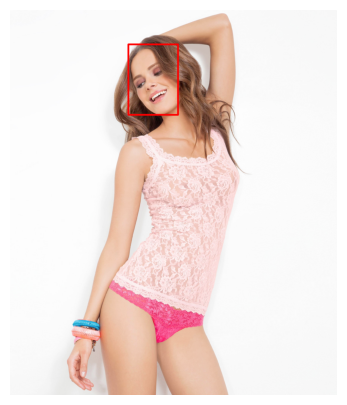

In [12]:
import matplotlib.pyplot as plt

img = cv2.cvtColor(cv2.imread(os.path.join(ex_live, png)), cv2.COLOR_BGR2RGB)
H, W = img.shape[:2]
x, y, w, h = [float(v) for v in open(bb_file).read().split()[:4]]
x, w = x * W / 224, w * W / 224
y, h = y * H / 224, h * H / 224
cv2.rectangle(img, (int(x), int(y)), (int(x + w), int(y + h)), (255, 0, 0), max(4, W // 200))
plt.figure(figsize=(5, 5)); plt.imshow(img); plt.axis('off'); plt.show()

In [13]:
from concurrent.futures import ThreadPoolExecutor

CACHE = r'C:\Code\cache'
os.makedirs(CACHE, exist_ok=True)
MARGIN = 0.3   # extra context around the face box

def load_face(item):
    path, label, subj = item
    try:
        img = cv2.imread(path)
        if img is None:
            return None
        H, W = img.shape[:2]
        bb = path.rsplit('.', 1)[0] + '_BB.txt'
        x, y, w, h = [float(v) for v in open(bb).read().split()[:4]]
        x, w = x * W / 224, w * W / 224
        y, h = y * H / 224, h * H / 224
        x0 = max(0, int(x - MARGIN * w)); y0 = max(0, int(y - MARGIN * h))
        x1 = min(W, int(x + w + MARGIN * w)); y1 = min(H, int(y + h + MARGIN * h))
        if x1 - x0 < 10 or y1 - y0 < 10:
            return None
        crop = cv2.resize(img[y0:y1, x0:x1], (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
        sx, sy = IMG_SIZE / (x1 - x0), IMG_SIZE / (y1 - y0)
        fb = [int((x - x0) * sx), int((y - y0) * sy), int((x + w - x0) * sx), int((y + h - y0) * sy)]
        fb = [max(0, min(IMG_SIZE, v)) for v in fb]
        return crop[:, :, ::-1], label, fb        # BGR -> RGB
    except Exception:
        return None

def build_cache(items, name, workers=8):
    with ThreadPoolExecutor(workers) as ex:
        res = list(tqdm(ex.map(load_face, items), total=len(items)))
    keep = [(r, it) for r, it in zip(res, items) if r is not None]
    X = np.stack([r[0] for r, _ in keep]).astype(np.uint8)
    y = np.array([r[1] for r, _ in keep], dtype=np.int64)
    fb = np.array([r[2] for r, _ in keep], dtype=np.int64)
    subj = np.array([it[2] for _, it in keep])
    np.savez(os.path.join(CACHE, name + '.npz'), X=X, y=y, fb=fb, subj=subj)
    print(name, X.shape, '| live:', int(y.sum()), '| skipped:', len(items) - len(keep))

In [14]:
import time
assert len(train_set) > 0 and len(val_set) > 0, 'train/val are empty - fix Cell 4b first'
t = time.time()
build_cache(train_set[:100], 'timing_test')
print('seconds per 100 images:', round(time.time() - t, 1))
print('estimated minutes for all:', round((time.time() - t) / 100 * (len(train_set) + len(val_set) + len(test_set)) / 60, 1))

100%|██████████| 100/100 [00:00<00:00, 661.48it/s]

timing_test (100, 128, 128, 3) | live: 44 | skipped: 0
seconds per 100 images: 0.2
estimated minutes for all: 0.7


In [15]:
build_cache(train_set, 'train')
build_cache(val_set, 'val')
build_cache(test_set, 'test')

100%|██████████| 13199/13199 [00:23<00:00, 556.10it/s]


train (13199, 128, 128, 3) | live: 4899 | skipped: 0


100%|██████████| 2382/2382 [00:01<00:00, 1295.21it/s]


val (2382, 128, 128, 3) | live: 809 | skipped: 0


100%|██████████| 8330/8330 [00:14<00:00, 586.57it/s]


test (8329, 128, 128, 3) | live: 3804 | skipped: 1


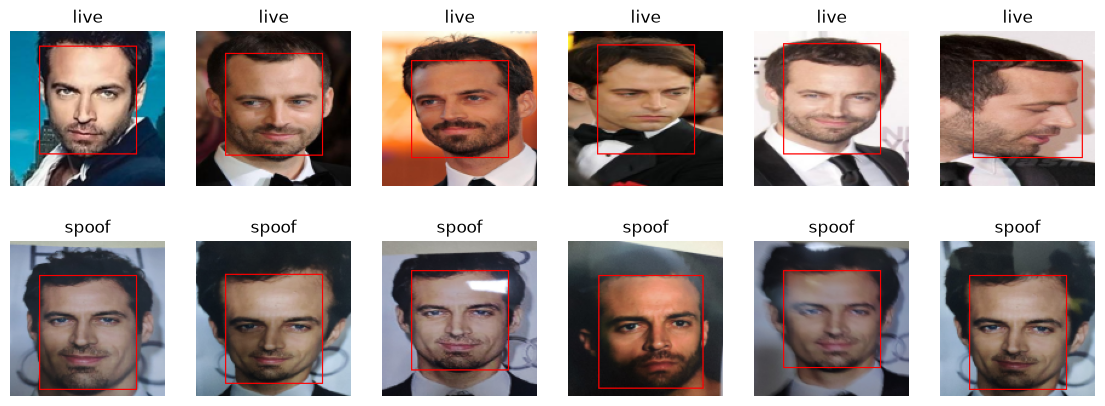

In [21]:
import matplotlib.pyplot as plt
d = np.load(os.path.join(CACHE, 'train.npz'))
fig, axes = plt.subplots(2, 6, figsize=(14, 5))
idx = list(np.where(d['y'] == 1)[0][:6]) + list(np.where(d['y'] == 0)[0][:6])
for ax, i in zip(axes.flat, idx):
    im = d['X'][i].copy()
    x0, y0, x1, y1 = d['fb'][i]
    cv2.rectangle(im, (x0, y0), (x1, y1), (255, 0, 0), 1)
    ax.imshow(im); ax.axis('off'); ax.set_title('live' if d['y'][i] else 'spoof')
plt.show()

In [ ]:
RESNET

In [20]:
import torchvision
from torchvision.models import resnet18, ResNet18_Weights

tr = np.load(os.path.join(CACHE, 'train.npz'))
va = np.load(os.path.join(CACHE, 'val.npz'))
te = np.load(os.path.join(CACHE, 'test.npz'))
Xtr, ytr = tr['X'], tr['y']
Xva, yva = va['X'], va['y']
Xte, yte, fbte = te['X'], te['y'], te['fb']

MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

def to_batch(Xu8):                       # numpy uint8 (N,H,W,3) -> normalised GPU tensor
    x = torch.from_numpy(Xu8).to(device).permute(0, 3, 1, 2).float() / 255
    return (x - MEAN) / STD

@torch.no_grad()
def predict_scores(model, X, bs=256):    # returns P(live) for each image
    model.eval(); out = []
    for i in range(0, len(X), bs):
        out.append(torch.sigmoid(model(to_batch(X[i:i + bs]))).squeeze(1).cpu())
    return torch.cat(out).numpy()

def error_rates(scores, y, thr):         # live = positive class
    pred_live = scores >= thr
    apcer = float(np.mean(pred_live[y == 0]))      # attacks accepted as live
    bpcer = float(np.mean(~pred_live[y == 1]))     # live faces rejected
    return apcer, bpcer, (apcer + bpcer) / 2       # ACER

def eer_threshold(scores, y):            # threshold where the two errors are equal
    ths = np.quantile(scores, np.linspace(0, 1, 1001))
    gaps = [abs(error_rates(scores, y, t)[0] - error_rates(scores, y, t)[1]) for t in ths]
    return float(ths[int(np.argmin(gaps))])

In [24]:
def make_resnet():
    m = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)   # ImageNet-pretrained start
    m.fc = nn.Linear(m.fc.in_features, 1)
    return m.to(device)

def train_resnet(epochs=6, bs=64, lr=1e-4, seed=0):
    torch.manual_seed(seed); np.random.seed(seed)
    model = make_resnet()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    pos_w = torch.tensor((ytr == 0).sum() / (ytr == 1).sum(), device=device, dtype=torch.float32)
    lossf = nn.BCEWithLogitsLoss(pos_weight=pos_w)
    scaler = torch.amp.GradScaler('cuda')
    best, best_state = 1.0, None
    for ep in range(epochs):
        model.train()
        perm = np.random.permutation(len(Xtr)); total = 0
        for i in tqdm(range(0, len(perm), bs), desc=f'epoch {ep+1}/{epochs}'):
            idx = np.sort(perm[i:i + bs])
            x = to_batch(Xtr[idx])
            flip = torch.rand(len(idx), device=device) < 0.5
            x[flip] = x[flip].flip(3)                           # random horizontal flip
            y = torch.from_numpy(ytr[idx]).float().to(device).unsqueeze(1)
            with torch.autocast('cuda', dtype=torch.float16):
                loss = lossf(model(x), y)
            opt.zero_grad(); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            total += loss.item() * len(idx)
        s = predict_scores(model, Xva)
        thr = eer_threshold(s, yva)
        val_acer = error_rates(s, yva, thr)[2]
        print(f'epoch {ep+1}: train loss {total/len(Xtr):.4f} | val ACER {val_acer:.4f}')
        if val_acer < best:
            best = val_acer
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    return model

resnet = train_resnet()
torch.save(resnet.state_dict(), os.path.join(CACHE, 'resnet18_seed0.pt'))

epoch 1/6: 100%|██████████| 207/207 [00:16<00:00, 12.57it/s]


epoch 1: train loss 0.1370 | val ACER 0.0244


epoch 2/6: 100%|██████████| 207/207 [00:15<00:00, 13.50it/s]


epoch 2: train loss 0.0306 | val ACER 0.0172


epoch 3/6: 100%|██████████| 207/207 [00:15<00:00, 13.50it/s]


epoch 3: train loss 0.0182 | val ACER 0.0207


... (2 outputs left out)

epoch 5/6: 100%|██████████| 207/207 [00:14<00:00, 13.81it/s]


epoch 5: train loss 0.0134 | val ACER 0.0207


epoch 6/6: 100%|██████████| 207/207 [00:14<00:00, 13.80it/s]


epoch 6: train loss 0.0065 | val ACER 0.0216


In [25]:
s_val = predict_scores(resnet, Xva)
THR_RESNET = eer_threshold(s_val, yva)           # chosen on val, never touched again

s_test = predict_scores(resnet, Xte)
a, b, acer = error_rates(s_test, yte, THR_RESNET)
print(f'ResNet-18 TEST  APCER {a:.4f} | BPCER {b:.4f} | ACER {acer:.4f}  (threshold from val = {THR_RESNET:.3f})')

thr_oracle = eer_threshold(s_test, yte)          # for reference only: best-case threshold on test
print(f'  with oracle test threshold: ACER {error_rates(s_test, yte, thr_oracle)[2]:.4f}')

ResNet-18 TEST  APCER 0.3503 | BPCER 0.0244 | ACER 0.1874  (threshold from val = 0.315)
  with oracle test threshold: ACER 0.1463


In [26]:
subs = sorted(os.listdir(os.path.join(BASE, 'train')))
random.Random(SEED).shuffle(subs)          # same shuffle as build_subset
used = set(subs[:400])                     # people already used for train/val
within_items = []
for s in subs[400:650]:                    # 250 unused train-split people
    items = list_subject_images('train', s)
    random.Random(SEED).shuffle(items)
    within_items += items[:40]
print('overlap with train/val people:', len(set(x[2] for x in within_items) & used))
build_cache(within_items, 'within')

wi = np.load(os.path.join(CACHE, 'within.npz'))
Xwi, ywi, fbwi = wi['X'], wi['y'], wi['fb']
s_wi = predict_scores(resnet, Xwi)
a, b, acer = error_rates(s_wi, ywi, THR_RESNET)
print(f'ResNet-18 WITHIN-SPLIT  APCER {a:.4f} | BPCER {b:.4f} | ACER {acer:.4f}')

overlap with train/val people: 0


100%|██████████| 9803/9803 [00:18<00:00, 537.39it/s]


within (9803, 128, 128, 3) | live: 3287 | skipped: 0
ResNet-18 WITHIN-SPLIT  APCER 0.0414 | BPCER 0.0225 | ACER 0.0320


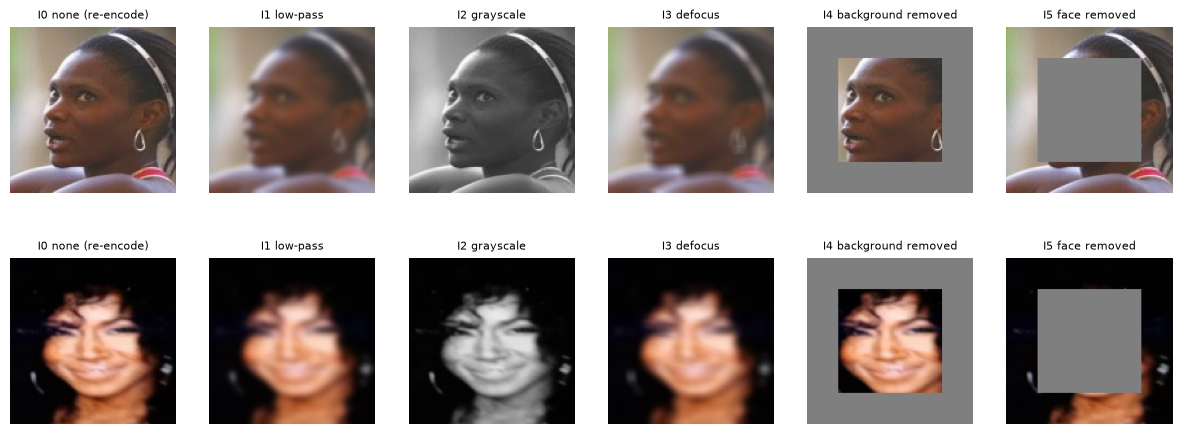

In [28]:
FILL = 127

def i0_identity(X, fb):                    # control: JPEG re-encode only
    out = np.empty_like(X)
    for i in range(len(X)):
        ok, enc = cv2.imencode('.jpg', X[i][:, :, ::-1], [cv2.IMWRITE_JPEG_QUALITY, 95])
        out[i] = cv2.imdecode(enc, 1)[:, :, ::-1]
    return out

def i1_lowpass(X, fb):                     # Gaussian blur removes fine texture / moire
    return np.stack([cv2.GaussianBlur(x, (0, 0), 2.0) for x in X])

def i2_gray(X, fb):                        # removes colour
    g = np.stack([cv2.cvtColor(x, cv2.COLOR_RGB2GRAY) for x in X])
    return np.repeat(g[..., None], 3, axis=3)

def i3_defocus(X, fb):                     # uniform (box) blur
    return np.stack([cv2.blur(x, (7, 7)) for x in X])

def i4_no_background(X, fb):               # keep face box, blank everything else
    out = np.full_like(X, FILL)
    for i, (x0, y0, x1, y1) in enumerate(fb):
        out[i, y0:y1, x0:x1] = X[i, y0:y1, x0:x1]
    return out

def i5_no_face(X, fb):                     # blank the face box, keep the context
    out = X.copy()
    for i, (x0, y0, x1, y1) in enumerate(fb):
        out[i, y0:y1, x0:x1] = FILL
    return out

INTERVENTIONS = {'I0 none (re-encode)': i0_identity, 'I1 low-pass': i1_lowpass,
                 'I2 grayscale': i2_gray, 'I3 defocus': i3_defocus,
                 'I4 background removed': i4_no_background, 'I5 face removed': i5_no_face}

# Look at them
import matplotlib.pyplot as plt
fig, axes = plt.subplots(2, 6, figsize=(15, 5.5))
for r, idx in enumerate([int(np.where(yte == 1)[0][0]), int(np.where(yte == 0)[0][0])]):
    for c, (name, fn) in enumerate(INTERVENTIONS.items()):
        axes[r, c].imshow(fn(Xte[idx:idx+1], fbte[idx:idx+1])[0]); axes[r, c].axis('off')
        axes[r, c].set_title(name, fontsize=8)
plt.show()

In [29]:
import pandas as pd

def run_damage(scorer, thr, sets):
    rows = []
    for set_name, (X, y, fb) in sets.items():
        base = None
        for name, fn in INTERVENTIONS.items():
            s = scorer(fn(X, fb))
            a, b, acer = error_rates(s, y, thr)
            if base is None: base = acer
            cri = (acer - base) / (0.5 - base) if name != 'I0 none (re-encode)' else 0.0
            rows.append(dict(set=set_name, intervention=name, APCER=a, BPCER=b, ACER=acer, CRI=cri))
    return pd.DataFrame(rows)

SETS = {'within-split': (Xwi, ywi, fbwi), 'unseen test': (Xte, yte, fbte)}
res_resnet = run_damage(lambda X: predict_scores(resnet, X), THR_RESNET, SETS)
print(res_resnet.round(3).to_string(index=False))
res_resnet.to_csv(os.path.join(CACHE, 'results_resnet.csv'), index=False)

NameError: name 'THR_RESNET' is not defined

In [33]:
if 'ref unmodified' not in INTERVENTIONS:
    INTERVENTIONS = {'ref unmodified': (lambda X, fb: X), **INTERVENTIONS}

def run_damage(scorer, thr, sets):
    rows = []
    for set_name, (X, y, fb) in sets.items():
        base = None
        for name, fn in INTERVENTIONS.items():
            s = scorer(fn(X, fb))
            a, b, acer = error_rates(s, y, thr)
            if base is None: base = acer
            rows.append(dict(set=set_name, intervention=name, APCER=a, BPCER=b,
                             ACER=acer, CRI=(acer - base) / (0.5 - base)))
    return pd.DataFrame(rows)

res_resnet = run_damage(lambda X: predict_scores(resnet, X), THR_RESNET, SETS)
print(res_resnet.round(3).to_string(index=False))
res_resnet.to_csv(os.path.join(CACHE, 'results_resnet.csv'), index=False)

NameError: name 'THR_RESNET' is not defined

In [21]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class CDC(nn.Module):
    """
    Central Difference Convolution implementation.
    """
    def __init__(self, IC, OC, K=3, P=1, theta=0.7):
        super(CDC, self).__init__()
        self.vani = nn.Conv2d(IC, OC, kernel_size=K, padding=P)
        self.theta = theta

    def forward(self, x):
        # Calculate vanilla convolution output
        out_vanilla = self.vani(x)

        # Calculate central difference gradient term
        kernel_diff = self.vani.weight.sum(2).sum(2)
        kernel_diff = kernel_diff[:, :, None, None]
        out_CD = F.conv2d(input=x, weight=kernel_diff, padding=0)

        return out_vanilla - self.theta * out_CD

class CDCNBlock(nn.Module):
    """
    Standard block for CDCN consisting of CDC -> BatchNorm -> ReLU.
    """
    def __init__(self, in_channels, out_channels, theta=0.7):
        super(CDCNBlock, self).__init__()
        self.cdc = CDC(in_channels, out_channels, K=3, P=1, theta=theta)
        self.bn = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        return self.relu(self.bn(self.cdc(x)))

class CDCN(nn.Module):
    """
    Central Difference Convolutional Network (CDCN) for Face Anti-Spoofing.
    """
    def __init__(self, theta=0.7):
        super(CDCN, self).__init__()

        # Initial Feature Extraction
        self.stem = CDCNBlock(3, 64, theta=theta)

        # Low-level features
        self.low_block = nn.Sequential(
            CDCNBlock(64, 128, theta=theta),
            CDCNBlock(128, 196, theta=theta),
            CDCNBlock(196, 128, theta=theta),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
        )

        # Mid-level features
        self.mid_block = nn.Sequential(
            CDCNBlock(128, 128, theta=theta),
            CDCNBlock(128, 196, theta=theta),
            CDCNBlock(196, 128, theta=theta),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
        )

        # High-level features
        self.high_block = nn.Sequential(
            CDCNBlock(128, 128, theta=theta),
            CDCNBlock(128, 196, theta=theta),
            CDCNBlock(196, 128, theta=theta),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
        )

        # Depth Map Prediction Head
        self.head = nn.Sequential(
            CDCNBlock(384, 128, theta=theta),
            CDCNBlock(128, 64, theta=theta),
            CDC(64, 1, K=3, P=1, theta=theta)
        )

    def forward(self, x):
        # x shape: [Batch, 3, 256, 256]
        out_init = self.stem(x)

        # Extract multi-level features
        low_feat = self.low_block(out_init)   # Output shape: [Batch, 128, 128, 128]
        mid_feat = self.mid_block(low_feat)   # Output shape: [Batch, 128, 64, 64]
        high_feat = self.high_block(mid_feat) # Output shape: [Batch, 128, 32, 32]

        # Resize Low and Mid features to match High feature dimensions (32x32)
        low_feat_resized = F.interpolate(low_feat, size=(32, 32), mode='bilinear', align_corners=False)
        mid_feat_resized = F.interpolate(mid_feat, size=(32, 32), mode='bilinear', align_corners=False)

        # Concatenate multi-level features (128 + 128 + 128 = 384 channels)
        concat_feat = torch.cat((low_feat_resized, mid_feat_resized, high_feat), dim=1) # [Batch, 384, 32, 32]

        # Predict grayscale facial depth map
        depth_map = self.head(concat_feat) # [Batch, 1, 32, 32]

        return depth_map
class ContrastiveDepthLoss(nn.Module):
    """
    Calculates the spatial gradient differences between predicted and ground truth depth maps.
    """
    def __init__(self):
        super(ContrastiveDepthLoss, self).__init__()
        # Define Sobel kernels for X and Y directions
        kernel_x = torch.tensor([[-1.0, 0.0, 1.0],
                                 [-2.0, 0.0, 2.0],
                                 [-1.0, 0.0, 1.0]]).view(1, 1, 3, 3)
        kernel_y = torch.tensor([[-1.0, -2.0, -1.0],
                                 [ 0.0,  0.0,  0.0],
                                 [ 1.0,  2.0,  1.0]]).view(1, 1, 3, 3)

        self.register_buffer('weight_x', kernel_x)
        self.register_buffer('weight_y', kernel_y)
        self.l1_loss = nn.L1Loss()

    def forward(self, pred, target):
        # Extract gradients for predictions
        pred_grad_x = F.conv2d(pred, self.weight_x, padding=1)
        pred_grad_y = F.conv2d(pred, self.weight_y, padding=1)

        # Extract gradients for ground truth
        target_grad_x = F.conv2d(target, self.weight_x, padding=1)
        target_grad_y = F.conv2d(target, self.weight_y, padding=1)

        # Compute L1 distance between gradients
        loss_x = self.l1_loss(pred_grad_x, target_grad_x)
        loss_y = self.l1_loss(pred_grad_y, target_grad_y)

        return loss_x + loss_y

class CDCNLoss(nn.Module):
    """
    Overall loss combining MSE and Contrastive Depth Loss.
    """
    def __init__(self):
        super(CDCNLoss, self).__init__()
        self.mse = nn.MSELoss()
        self.cdl = ContrastiveDepthLoss()

    def forward(self, pred, target):
        return self.mse(pred, target) + self.cdl(pred, target)


In [22]:
def cdcn_forward(self, x):
    out_init = self.stem(x)
    low_feat = self.low_block(out_init)      # 128 -> 64
    mid_feat = self.mid_block(low_feat)      # 64  -> 32
    high_feat = self.high_block(mid_feat)    # 32  -> 16 (at 128x128 input)

    size = (32, 32)
    feats = [F.interpolate(f, size=size, mode='bilinear', align_corners=False)
             for f in (low_feat, mid_feat, high_feat)]
    concat_feat = torch.cat(feats, dim=1)    # [B, 384, 32, 32]
    return self.head(concat_feat)            # [B, 1, 32, 32]

CDCN.forward = cdcn_forward

# quick shape test before training
m = CDCN().to(device)
print(m(torch.randn(2, 3, 128, 128, device=device)).shape)   # expect [2, 1, 32, 32]

torch.Size([2, 1, 32, 32])


In [23]:
from torch.utils.checkpoint import checkpoint

def cdcn_forward_ckpt(self, x):
    out_init = self.stem(x)
    if self.training:
        low  = checkpoint(self.low_block,  out_init, use_reentrant=False)
        mid  = checkpoint(self.mid_block,  low,      use_reentrant=False)
        high = checkpoint(self.high_block, mid,      use_reentrant=False)
    else:
        low = self.low_block(out_init); mid = self.mid_block(low); high = self.high_block(mid)
    feats = [F.interpolate(f, size=(32, 32), mode='bilinear', align_corners=False)
             for f in (low, mid, high)]
    return self.head(torch.cat(feats, dim=1))

CDCN.forward = cdcn_forward_ckpt

In [24]:
def depth_targets(y):                        # live -> all ones, spoof -> all zeros
    t = torch.from_numpy(y).float().to(device).view(-1, 1, 1, 1)
    return t.expand(-1, 1, 32, 32).contiguous()

@torch.no_grad()
def predict_scores_cdcn(model, X, bs=128):   # score = mean of predicted depth map
    model.eval(); out = []
    for i in range(0, len(X), bs):
        out.append(model(to_batch(X[i:i + bs])).float().mean(dim=(1, 2, 3)).cpu())
    return torch.cat(out).numpy()

def train_cdcn(epochs=8, bs=8, accum=4, lr=1e-4, seed=0):
    torch.manual_seed(seed); np.random.seed(seed)
    model = CDCN(theta=0.7).to(device)
    lossf = CDCNLoss().to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)
    scaler = torch.amp.GradScaler('cuda')
    best, best_state = 1.0, None
    for ep in range(epochs):
        model.train()
        perm = np.random.permutation(len(Xtr)); total = 0; step = 0
        opt.zero_grad()
        for i in tqdm(range(0, len(perm), bs), desc=f'epoch {ep+1}/{epochs}'):
            idx = np.sort(perm[i:i + bs])
            x = to_batch(Xtr[idx])
            flip = torch.rand(len(idx), device=device) < 0.5
            x[flip] = x[flip].flip(3)
            tgt = depth_targets(ytr[idx])
            with torch.autocast('cuda', dtype=torch.float16):
                pred = model(x)
            loss = lossf(pred.float(), tgt)
            scaler.scale(loss / accum).backward()
            step += 1
            if step % accum == 0:
                scaler.step(opt); scaler.update(); opt.zero_grad()
            total += loss.item() * len(idx)
        s = predict_scores_cdcn(model, Xva, bs=32)
        val_acer = error_rates(s, yva, eer_threshold(s, yva))[2]
        print(f'epoch {ep+1}: train loss {total/len(Xtr):.4f} | val ACER {val_acer:.4f}')
        if val_acer < best:
            best = val_acer
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        torch.cuda.empty_cache()
    model.load_state_dict(best_state)
    return model
cdcn = train_cdcn()
torch.save(cdcn.state_dict(), os.path.join(CACHE, 'cdcn_seed0.pt'))

THR_CDCN = eer_threshold(predict_scores_cdcn(cdcn, Xva), yva)
for nm, (X, y) in {'within-split': (Xwi, ywi), 'unseen test': (Xte, yte)}.items():
    a, b, acer = error_rates(predict_scores_cdcn(cdcn, X), y, THR_CDCN)
    print(f'CDCN {nm}: APCER {a:.4f} | BPCER {b:.4f} | ACER {acer:.4f}')

res_cdcn = run_damage(lambda X: predict_scores_cdcn(cdcn, X), THR_CDCN, SETS)
print(res_cdcn.round(3).to_string(index=False))
res_cdcn.to_csv(os.path.join(CACHE, 'results_cdcn.csv'), index=False)

epoch 1/8: 100%|██████████| 1650/1650 [06:14<00:00,  4.41it/s]


epoch 1: train loss 0.6025 | val ACER 0.3394


epoch 2/8: 100%|██████████| 1650/1650 [06:15<00:00,  4.40it/s]


epoch 2: train loss 0.4822 | val ACER 0.2360


epoch 3/8: 100%|██████████| 1650/1650 [06:18<00:00,  4.36it/s]


epoch 3: train loss 0.4709 | val ACER 0.2103


... (7 outputs left out)

epoch 7: train loss 0.4651 | val ACER 0.1783


epoch 8/8: 100%|██████████| 1650/1650 [06:24<00:00,  4.29it/s]


epoch 8: train loss 0.4649 | val ACER 0.2250


NameError: name 'Xwi' is not defined

In [25]:
import numpy as np, os
CACHE = r'C:\Code\cache'
wi = np.load(os.path.join(CACHE, 'within.npz'))
Xwi, ywi, fbwi = wi['X'], wi['y'], wi['fb']

for nm, (X, y) in {'within-split': (Xwi, ywi), 'unseen test': (Xte, yte)}.items():
    a, b, acer = error_rates(predict_scores_cdcn(cdcn, X, bs=32), y, THR_CDCN)
    print(f'CDCN {nm}: APCER {a:.4f} | BPCER {b:.4f} | ACER {acer:.4f}')

CDCN within-split: APCER 0.1634 | BPCER 0.1783 | ACER 0.1709
CDCN unseen test: APCER 0.4970 | BPCER 0.2119 | ACER 0.3544


In [32]:
def run_damage(scorer, thr, sets):
    rows = []
    for set_name, (X, y, fb) in sets.items():
        base = None
        for name, fn in INTERVENTIONS.items():
            s = scorer(fn(X, fb))
            a, b, acer = error_rates(s, y, thr)
            if base is None: base = acer
            rows.append(dict(set=set_name, intervention=name, APCER=a, BPCER=b,
                             ACER=acer, CRI=(acer - base) / (0.5 - base)))
    return pd.DataFrame(rows)

thr_or = eer_threshold(predict_scores_cdcn(cdcn, Xte, bs=32), yte)
print('CDCN unseen, oracle threshold ACER:',
      round(error_rates(predict_scores_cdcn(cdcn, Xte, bs=32), yte, thr_or)[2], 4))

SETS = {'within-split': (Xwi, ywi, fbwi), 'unseen test': (Xte, yte, fbte)}
res_cdcn = run_damage(lambda X: predict_scores_cdcn(cdcn, X, bs=32), THR_CDCN, SETS)
print(res_cdcn.round(3).to_string(index=False))
res_cdcn.to_csv(r'C:\Code\cache\results_cdcn.csv', index=False)

CDCN unseen, oracle threshold ACER: 0.3598
         set          intervention  APCER  BPCER  ACER   CRI
within-split        ref unmodified  0.163  0.178 0.171 0.000
within-split   I0 none (re-encode)  0.175  0.175 0.175 0.013
within-split           I1 low-pass  0.093  0.399 0.246 0.228
within-split          I2 grayscale  0.053  0.667 0.360 0.574
within-split            I3 defocus  0.095  0.396 0.245 0.227
within-split I4 background removed  0.000  0.998 0.499 0.998
within-split       I5 face removed  0.186  0.161 0.173 0.007
 unseen test        ref unmodified  0.497  0.212 0.354 0.000
 unseen test   I0 none (re-encode)  0.511  0.213 0.362 0.052
 unseen test           I1 low-pass  0.335  0.461 0.398 0.297
 unseen test          I2 grayscale  0.168  0.693 0.431 0.524
 unseen test            I3 defocus  0.338  0.462 0.400 0.312
 unseen test I4 background removed  0.000  1.000 0.500 1.001
 unseen test       I5 face removed  0.524  0.190 0.357 0.018


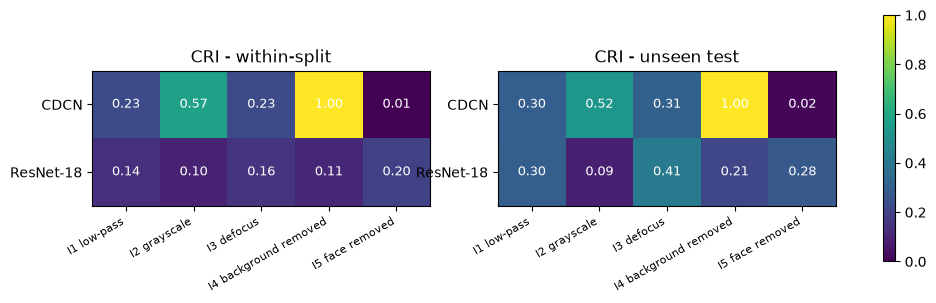

In [34]:
import pandas as pd, matplotlib.pyplot as plt
C = r'C:\Code\cache'
r = pd.read_csv(f'{C}/results_resnet.csv'); r['model'] = 'ResNet-18'
c = pd.read_csv(f'{C}/results_cdcn.csv');   c['model'] = 'CDCN'
df = pd.concat([r, c])
df.to_csv(f'{C}/results_all.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, s in zip(axes, ['within-split', 'unseen test']):
    p = df[(df.set == s) & (~df.intervention.isin(['ref unmodified', 'I0 re-encode', 'I0 none (re-encode)']))]
    p = p.pivot(index='model', columns='intervention', values='CRI')
    im = ax.imshow(p.values, vmin=0, vmax=1, cmap='viridis')
    ax.set_xticks(range(p.shape[1])); ax.set_xticklabels(p.columns, rotation=30, ha='right', fontsize=8)
    ax.set_yticks(range(p.shape[0])); ax.set_yticklabels(p.index); ax.set_title(f'CRI - {s}')
    for i in range(p.shape[0]):
        for j in range(p.shape[1]):
            ax.text(j, i, f'{p.values[i, j]:.2f}', ha='center', va='center', color='w', fontsize=9)
plt.colorbar(im, ax=axes, shrink=0.8); plt.savefig(f'{C}/fig_cri.png', dpi=200, bbox_inches='tight'); plt.show()

In [38]:
import numpy as np, os, torch, torch.nn as nn, torch.nn.functional as F
from torchvision.models import resnet18
C = r'C:\Code\cache'

def no_inplace(m):
    for l in m.modules():
        if isinstance(l, nn.ReLU): l.inplace = False
    return m

def make_resnet_empty():
    m = resnet18(weights=None); m.fc = nn.Linear(m.fc.in_features, 1); return m

resnet = make_resnet_empty()
resnet.load_state_dict(torch.load(f'{C}/resnet18_seed0.pt', map_location=device))
cdcn = CDCN(theta=0.7)
cdcn.load_state_dict(torch.load(f'{C}/cdcn_seed0.pt', map_location=device))

torch.manual_seed(123)
resnet_rand, cdcn_rand = make_resnet_empty(), CDCN(theta=0.7)    # random weights = "no information" control

resnet, cdcn, resnet_rand, cdcn_rand = [no_inplace(m).to(device).eval() for m in (resnet, cdcn, resnet_rand, cdcn_rand)]
print('models ready')

models ready


In [39]:
def gradcam(model, target, use_input, score_fn, X, bs=8):
    store, cams = {}, []
    if use_input:
        def hook(m, inp): inp[0].retain_grad(); store['a'] = inp[0]
        h = target.register_forward_pre_hook(hook)
    else:
        def hook(m, inp, out): out.retain_grad(); store['a'] = out
        h = target.register_forward_hook(hook)
    for i in range(0, len(X), bs):
        x = to_batch(np.array(X[i:i + bs]))
        model.zero_grad()
        score_fn(model(x)).sum().backward()
        A, G = store['a'], store['a'].grad
        cam = F.relu((G.mean(dim=(2, 3), keepdim=True) * A).sum(1, keepdim=True))
        cam = F.interpolate(cam, size=(128, 128), mode='bilinear', align_corners=False)
        cams.append(cam.detach().squeeze(1).cpu().numpy())
    h.remove()
    return np.concatenate(cams)

# ResNet: layer3 (8x8 map; layer4 would be only 4x4 at 128px). CDCN: the 32x32 feature stack feeding the head.
MODELS = {
    'ResNet-18':        (resnet,      resnet.layer3,      False, lambda o: o.squeeze(1)),
    'ResNet-18 random': (resnet_rand, resnet_rand.layer3, False, lambda o: o.squeeze(1)),
    'CDCN':             (cdcn,        cdcn.head,          True,  lambda o: o.mean(dim=(1, 2, 3))),
    'CDCN random':      (cdcn_rand,   cdcn_rand.head,     True,  lambda o: o.mean(dim=(1, 2, 3))),
}

rng = np.random.RandomState(0)
idx_live  = np.sort(rng.choice(np.where(yte == 1)[0], 300, replace=False))
idx_spoof = np.sort(rng.choice(np.where(yte == 0)[0], 300, replace=False))
XL, XS = np.array(Xte[idx_live]), np.array(Xte[idx_spoof])
FL, FS = fbte[idx_live], fbte[idx_spoof]

CAMS = {}
for name, (m, tgt, use_in, sf) in MODELS.items():
    CAMS[name] = {'live': gradcam(m, tgt, use_in, sf, XL), 'spoof': gradcam(m, tgt, use_in, sf, XS)}
    print(name, 'done')
np.savez_compressed(f'{C}/gradcam_maps.npz', **{f'{n}|{k}': v for n, d in CAMS.items() for k, v in d.items()})

def region_masks(fb, size=128, ring=0.25):
    x0, y0, x1, y1 = [int(v) for v in fb]; w, h = x1 - x0, y1 - y0
    face = np.zeros((size, size), bool); face[y0:y1, x0:x1] = True
    ext = np.zeros((size, size), bool)
    ext[max(0, int(y0 - ring * h)):min(size, int(y1 + ring * h)), max(0, int(x0 - ring * w)):min(size, int(x1 + ring * w))] = True
    return face, ext & ~face, ~ext

def profile(cams, fbs):
    rows = []
    for cam, fb in zip(cams, fbs):
        if cam.sum() <= 1e-8: continue
        cam = cam / cam.sum(); f, m, b = region_masks(fb)
        rows.append([cam[f].sum(), cam[m].sum(), cam[b].sum(), f.mean(), m.mean(), b.mean()])
    return np.mean(rows, axis=0)

out = []
for name in MODELS:
    for cls, cams, fbs in (('live', CAMS[name]['live'], FL), ('spoof', CAMS[name]['spoof'], FS)):
        p = profile(cams, fbs)
        out.append(dict(model=name, images=cls, face=p[0], margin=p[1], background=p[2],
                        face_area=p[3], margin_area=p[4], bg_area=p[5]))
prof = pd.DataFrame(out)
print(prof.round(3).to_string(index=False))
prof.to_csv(f'{C}/gradcam_profile.csv', index=False)

ResNet-18 done
ResNet-18 random done
CDCN done
CDCN random done
           model images  face  margin  background  face_area  margin_area  bg_area
       ResNet-18   live 0.469   0.451       0.079       0.40        0.488    0.112
       ResNet-18  spoof 0.395   0.497       0.108       0.42        0.476    0.104
ResNet-18 random   live 0.371   0.504       0.125       0.40        0.488    0.112
ResNet-18 random  spoof 0.393   0.492       0.115       0.42        0.476    0.104
            CDCN   live 0.235   0.461       0.304       0.40        0.488    0.112
            CDCN  spoof 0.249   0.459       0.292       0.42        0.476    0.104
     CDCN random   live 0.344   0.323       0.333       0.40        0.488    0.112
     CDCN random  spoof 0.364   0.352       0.284       0.42        0.476    0.104


In [40]:
FRACS = [0.05, 0.10, 0.20, 0.30, 0.50]
SCORERS = {'ResNet-18': lambda X: predict_scores(resnet, X),
           'CDCN':      lambda X: predict_scores_cdcn(cdcn, X, bs=32)}

def deletion(scorer, X, order_maps):
    base = scorer(X); n = 128 * 128; res = []
    for f in FRACS:
        k = int(f * n); Xd = X.copy()
        for i in range(len(Xd)):
            idx = np.argsort(-order_maps[i].ravel())[:k]
            flat = Xd[i].reshape(-1, 3); flat[idx] = FILL
        res.append(float(np.mean(base - scorer(Xd)) / np.mean(base)))   # fraction of live score lost
    return res

rr = np.random.RandomState(1)
noise = lambda c: c + 1e-9 * rr.rand(*c.shape)
rows = []
for name, rand_name in (('ResNet-18', 'ResNet-18 random'), ('CDCN', 'CDCN random')):
    sc = SCORERS[name]
    curves = {
        'trained-model map':    deletion(sc, XL, noise(CAMS[name]['live'])),
        'random-weights map':   deletion(sc, XL, noise(CAMS[rand_name]['live'])),
        'random pixels':        deletion(sc, XL, rr.rand(len(XL), 128, 128)),
    }
    for k, v in curves.items():
        rows.append(dict(model=name, deleted_by=k, **{f'{int(f*100)}%': round(x, 3) for f, x in zip(FRACS, v)},
                         mean=round(float(np.mean(v)), 3)))
dele = pd.DataFrame(rows); print(dele.to_string(index=False))
dele.to_csv(f'{C}/gradcam_deletion.csv', index=False)

    model         deleted_by     5%    10%    20%    30%    50%   mean
ResNet-18  trained-model map  0.068  0.126  0.245  0.331  0.374  0.229
ResNet-18 random-weights map  0.027  0.049  0.101  0.166  0.336  0.136
ResNet-18      random pixels  0.015 -0.005 -0.007 -0.006  0.032  0.006
     CDCN  trained-model map  0.006  0.008  0.007  0.009  0.009  0.008
     CDCN random-weights map -0.000 -0.001 -0.003 -0.005 -0.005 -0.003
     CDCN      random pixels -0.005 -0.007 -0.009 -0.010 -0.008 -0.008


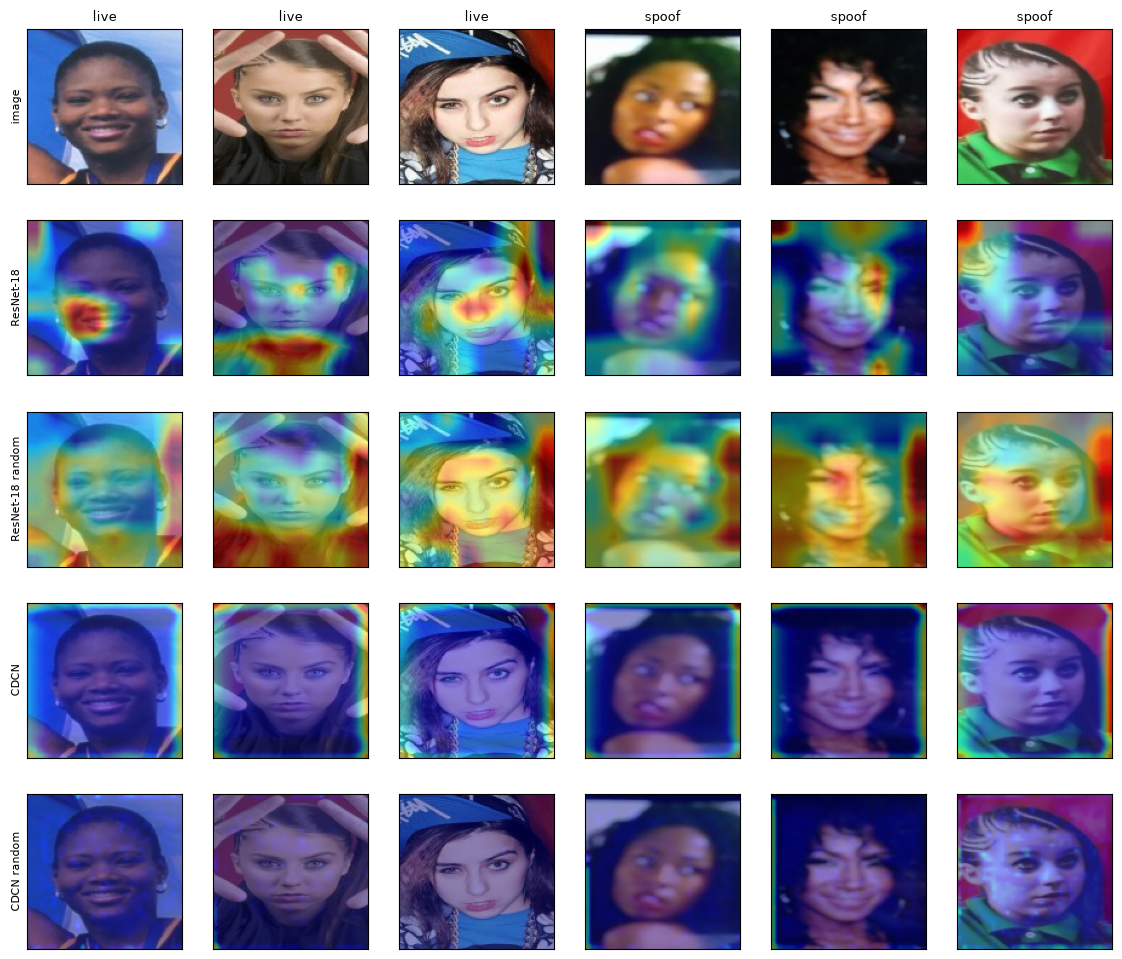

In [41]:
import matplotlib.pyplot as plt
def overlay(img, cam):
    c = (cam / (cam.max() + 1e-8) * 255).astype(np.uint8)
    heat = cv2.applyColorMap(c, cv2.COLORMAP_JET)[:, :, ::-1]
    return (0.55 * img + 0.45 * heat).astype(np.uint8)

n = 3
imgs = list(XL[:n]) + list(XS[:n])
fig, ax = plt.subplots(5, 2 * n, figsize=(14, 12))
for j, im in enumerate(imgs):
    ax[0, j].imshow(im); ax[0, j].set_title('live' if j < n else 'spoof', fontsize=9)
    for r, name in enumerate(MODELS, start=1):
        cam = CAMS[name]['live' if j < n else 'spoof'][j % n]
        ax[r, j].imshow(overlay(im, cam))
        if j == 0: ax[r, j].set_ylabel(name, fontsize=8)
for a in ax.flat: a.set_xticks([]); a.set_yticks([])
ax[0, 0].set_ylabel('image', fontsize=8)
plt.savefig(f'{C}/fig_gradcam.png', dpi=200, bbox_inches='tight'); plt.show()